# 03 — Modelos: comparação na validação

Treina os modelos no período de treino e compara no de validação (separação feita em `02_separacao.ipynb`). O período de **teste não é carregado aqui**: ele fica guardado para o resultado final, na Etapa 4.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from lightgbm import LGBMClassifier

import graficos
from avaliacao import metricas, metricas_de_acerto, nota_da_tabela, taxa_no_topo

graficos.aplicar_estilo()

treino = pd.read_parquet("../data/processed/treino.parquet")
validacao = pd.read_parquet("../data/processed/validacao.parquet")

alvo = "is_canceled"
variaveis = treino.columns.drop([alvo, "arrival_date"])
categoricas = treino[variaveis].select_dtypes(exclude="number").columns.tolist()
numericas = treino[variaveis].select_dtypes(include="number").columns.tolist()

X_treino, y_treino = treino[variaveis], treino[alvo]
X_validacao, y_validacao = validacao[variaveis], validacao[alvo]
print(f"{len(categoricas)} categóricas, {len(numericas)} numéricas")

10 categóricas, 12 numéricas


## 3.2 Métricas e pontos de comparação

Cada modelo dá uma nota de risco (probabilidade de cancelar) para cada reserva. Três métricas:
- **ROC-AUC:** a chance de o modelo dar nota maior a uma reserva que cancela do que a uma que não cancela. 0,5 é sorteio; 1 é perfeito.
- **PR-AUC:** mede o acerto olhando só para as canceladas. O ponto de partida é a própria taxa de cancelamento (28% na validação), então é mais exigente quando a classe que interessa é minoria.
- **Cancelam no top 10%:** das 10% reservas com maior nota, quantas cancelaram de fato. É a métrica do uso: se o hotel só consegue ligar para 10% das reservas, quantas ligações caem numa reserva que ia cancelar.

In [2]:
# taxa_no_topo e metricas ficam em avaliacao.py (usadas também no notebook 04)
resultados = []


def avaliar(nome, prob):
    """Calcula as três métricas na validação, guarda e devolve a tabela com todos os modelos até agora."""
    resultados.append({"modelo": nome, **metricas(y_validacao, prob)})
    return pd.DataFrame(resultados).set_index("modelo").round(3)

**Pontos de comparação, antes de qualquer modelo:**
1. **Taxa média** — a mesma nota para todas as reservas. É o equivalente a sortear.
2. **Regra da antecedência** — a nota é o próprio `lead_time`: quanto mais cedo a reserva, mais risco.
3. **Tabela segmento × antecedência** — a taxa de cancelamento do treino em cada combinação de segmento e faixa de antecedência. É o que um analista montaria numa planilha.

Um modelo só vale a pena se superar a tabela com folga.

In [3]:
avaliar("taxa média", np.full(len(y_validacao), y_treino.mean()))
avaliar("regra: antecedência", X_validacao["lead_time"])
avaliar("tabela: segmento × antecedência", nota_da_tabela(X_treino, y_treino, X_validacao))

,ROC-AUC,PR-AUC,cancelam no top 10%
modelo,,,
taxa média,0.500,0.284,0.284
regra: antecedência,0.682,0.430,0.509
tabela: segmento × antecedência,0.735,0.466,0.556


Sorteando, 28% das ligações cairiam numa reserva que ia cancelar. Só com a antecedência isso sobe para 51%, e a tabela de segmento × antecedência chega a **56%**. Essa é a régua para os modelos.

## 3.3 Regressão logística

O modelo mais simples: soma o peso de cada variável. Antes dele, um preparo dos dados:
- **Categorias** viram colunas de 0/1 (*one-hot*). Categorias com menos de 50 reservas no treino — a maioria das agências e empresas — vão juntas para um grupo "outras". Uma agência que só aparece na validação também cai nesse grupo, em vez de quebrar o modelo.
- **Números** são padronizados (média 0, desvio 1), para nenhuma variável pesar mais só por estar numa escala maior.

O preparo fica dentro de um `Pipeline`: ele aprende só com o treino (quais categorias existem, médias e desvios) e aplica o mesmo na validação, sem espiar os dados de lá.

In [4]:
preparo = ColumnTransformer([
    ("categoricas", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), categoricas),
    ("numericas", StandardScaler(), numericas),
])

# clone() dá a cada modelo a sua própria cópia do preparo
logistica = make_pipeline(clone(preparo), LogisticRegression(max_iter=2000)).fit(X_treino, y_treino)
avaliar("regressão logística", logistica.predict_proba(X_validacao)[:, 1])

,ROC-AUC,PR-AUC,cancelam no top 10%
modelo,,,
taxa média,0.500,0.284,0.284
regra: antecedência,0.682,0.430,0.509
tabela: segmento × antecedência,0.735,0.466,0.556
regressão logística,0.790,0.629,0.745


A regressão logística dá um salto grande sobre a tabela: **74,5%** de cancelamentos no top 10% (contra 56%) e ROC-AUC de 0,79 (contra 0,74).

## 3.4 Modelos de árvore: random forest e LightGBM

Os dois combinam centenas de árvores de decisão. Diferente da regressão logística, eles pegam **combinações** de variáveis sozinhos — por exemplo, antecedência longa pesar mais em um segmento do que em outro.
- **Random forest:** muitas árvores independentes, cada uma treinada numa amostra diferente; a nota final é a média.
- **LightGBM:** árvores em sequência, cada uma corrigindo os erros das anteriores (*gradient boosting*).

Usam o mesmo preparo da regressão logística. A padronização dos números não muda nada para árvores, mas manter um preparo só deixa a comparação mais limpa.

In [5]:
floresta = make_pipeline(
    clone(preparo),
    RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42),
).fit(X_treino, y_treino)
avaliar("random forest", floresta.predict_proba(X_validacao)[:, 1])

lightgbm = make_pipeline(
    clone(preparo),
    LGBMClassifier(n_estimators=500, learning_rate=0.05, random_state=42, verbose=-1),
).fit(X_treino, y_treino)
avaliar("LightGBM", lightgbm.predict_proba(X_validacao)[:, 1])

,ROC-AUC,PR-AUC,cancelam no top 10%
modelo,,,
taxa média,0.500,0.284,0.284
regra: antecedência,0.682,0.430,0.509
tabela: segmento × antecedência,0.735,0.466,0.556
regressão logística,0.790,0.629,0.745
random forest,0.812,0.632,0.729
LightGBM,0.815,0.647,0.741


Os modelos de árvore ganham da regressão logística no ROC-AUC (0,81 contra 0,79) e no PR-AUC. No top 10%, os três ficam praticamente empatados, entre 73% e 75%.

## 3.5 Comparação, ajuste e escolha

**Sobreajuste:** um modelo que vai muito melhor no treino do que na validação decorou o treino.

In [6]:
modelos = {"regressão logística": logistica, "random forest": floresta, "LightGBM": lightgbm}

pd.DataFrame({
    "ROC-AUC treino": {nome: roc_auc_score(y_treino, m.predict_proba(X_treino)[:, 1]) for nome, m in modelos.items()},
    "ROC-AUC validação": {nome: roc_auc_score(y_validacao, m.predict_proba(X_validacao)[:, 1]) for nome, m in modelos.items()},
}).round(3)

,ROC-AUC treino,ROC-AUC validação
regressão logística,0.792,0.790
random forest,0.899,0.812
LightGBM,0.892,0.815


A regressão logística tem o mesmo desempenho no treino e na validação. Os modelos de árvore vão bem melhor no treino (0,90 contra 0,81): decoram parte do treino, mas mesmo assim são os melhores na validação.

**Ajuste leve do LightGBM:** algumas combinações de tamanho das árvores (`num_leaves`), taxa de aprendizado e número de árvores, comparadas na validação.

In [7]:
ajuste = []
for folhas, taxa, arvores in [(15, 0.05, 300), (31, 0.05, 300), (63, 0.05, 300), (15, 0.02, 1500), (31, 0.02, 1500)]:
    modelo = make_pipeline(
        clone(preparo),
        LGBMClassifier(num_leaves=folhas, learning_rate=taxa, n_estimators=arvores, random_state=42, verbose=-1),
    ).fit(X_treino, y_treino)
    prob = modelo.predict_proba(X_validacao)[:, 1]
    ajuste.append({
        "num_leaves": folhas, "learning_rate": taxa, "n_estimators": arvores,
        "ROC-AUC": roc_auc_score(y_validacao, prob),
        "PR-AUC": average_precision_score(y_validacao, prob),
        "cancelam no top 10%": taxa_no_topo(y_validacao, prob),
    })
pd.DataFrame(ajuste).round(3)

,num_leaves,learning_rate,n_estimators,ROC-AUC,PR-AUC,cancelam no top 10%
0,15,0.05,300,0.817,0.648,0.738
1,31,0.05,300,0.817,0.648,0.745
2,63,0.05,300,0.814,0.642,0.733
3,15,0.02,1500,0.816,0.650,0.744
4,31,0.02,1500,0.814,0.647,0.740


Todas as combinações ficam dentro de ±0,005 de ROC-AUC da configuração do bloco 3.4 — diferença do tamanho do ruído. Escolher a "melhor" aqui seria otimizar o acaso; **fica a configuração original** (500 árvores, taxa 0,05).

**Comparação final na validação**

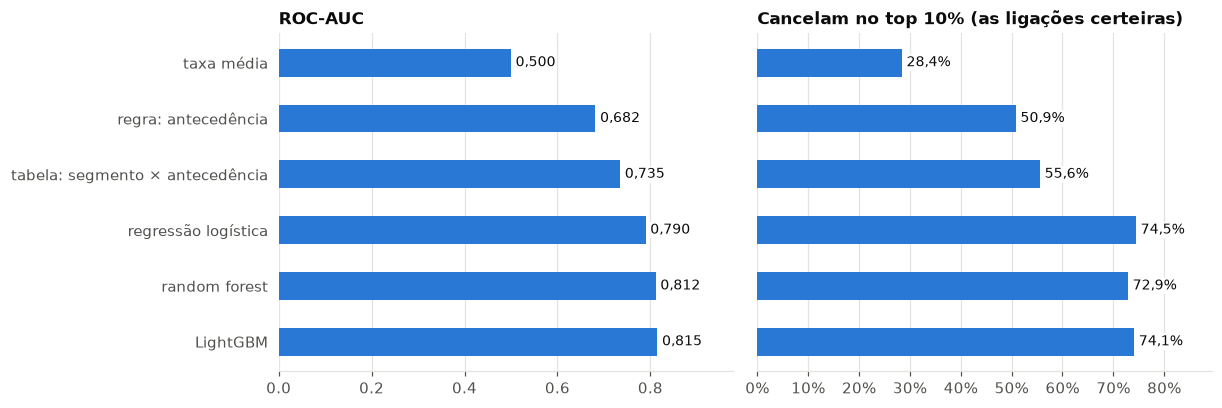

In [8]:
tabela = pd.DataFrame(resultados).set_index("modelo")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
graficos.barras_horizontais(ax1, tabela["ROC-AUC"], "ROC-AUC", formato=lambda v: f"{v:.3f}".replace(".", ","))
graficos.barras_horizontais(ax2, tabela["cancelam no top 10%"], "Cancelam no top 10% (as ligações certeiras)")
plt.show()

**E em taxa de acerto?** Acurácia, precisão, recall e F1 dos três modelos, transformando a probabilidade em sim/não com o limiar padrão de 0,5 (a escolha do limiar fica para o notebook 04). Para comparar, dois chutes: dizer que nenhuma reserva cancela e dizer que todas cancelam.

In [9]:
previsoes = {
    "chutar sempre 'não cancela'": np.zeros(len(y_validacao), dtype=bool),
    "chutar sempre 'cancela'": np.ones(len(y_validacao), dtype=bool),
    **{nome: m.predict_proba(X_validacao)[:, 1] >= 0.5 for nome, m in modelos.items()},
}
pd.DataFrame({nome: metricas_de_acerto(y_validacao, previsto) for nome, previsto in previsoes.items()}).T.round(3)

,acurácia,precisão,recall,F1
chutar sempre 'não cancela',0.716,0.000,0.000,0.000
chutar sempre 'cancela',0.284,0.284,1.000,0.443
regressão logística,0.772,0.716,0.328,0.450
random forest,0.779,0.702,0.388,0.499
LightGBM,0.784,0.684,0.448,0.541


O LightGBM também é o melhor nessas métricas: acurácia de 78,4% e F1 de 0,54, contra 77,2% e 0,45 da regressão logística. Mas a acurácia sozinha diz pouco: chutar que ninguém cancela já acerta 71,6%, porque a maioria das reservas não cancela. E com o limiar 0,5 os modelos pegam menos da metade dos cancelamentos (recall de 33% a 45%) — o notebook 04 mostra o que muda com outro limiar.

**Escolha: LightGBM.** É o melhor em ROC-AUC (0,815) e PR-AUC (0,647), empata no top 10% (74%) e treina em segundos. A regressão logística fica como referência: é quase tão boa no top 10% e mais fácil de explicar.

Na prática: ligando para as 10% reservas mais arriscadas, **74% das ligações caem numa reserva que ia cancelar** — contra 28% sorteando e 56% com a tabela de segmento × antecedência.

Próximo passo (Etapa 4): escolher o limiar de decisão pelo custo, explicar o que o modelo usa e só então avaliar no teste.

O modelo escolhido fica salvo em `models/` para o notebook 04 usar exatamente o mesmo, sem treinar de novo.

In [10]:
joblib.dump(lightgbm, "../models/lightgbm.joblib")

['../models/lightgbm.joblib']

## 3.6 Quanto o vazamento inflaria o resultado

Na auditoria (notebook 01), 6 colunas ficaram de fora porque só são conhecidas depois da reserva. E se elas tivessem ficado? O mesmo LightGBM, nos mesmos períodos, com e sem essas colunas.

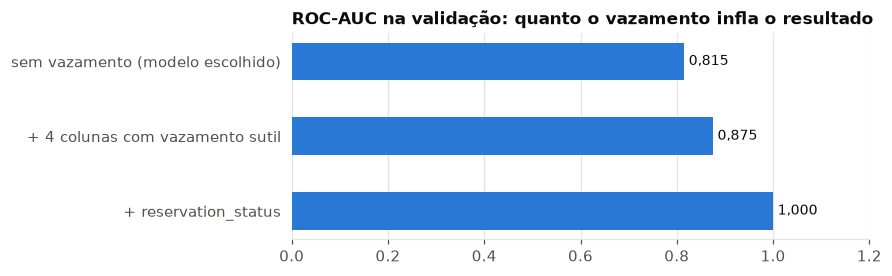

,ROC-AUC,PR-AUC,cancelam no top 10%
sem vazamento (modelo escolhido),0.815,0.647,0.741
+ 4 colunas com vazamento sutil,0.875,0.721,0.807
+ reservation_status,1.000,1.000,1.000


In [11]:
completas = pd.read_parquet("../data/processed/reservas_completas.parquet")
treino_completo = completas[completas["arrival_date"] < "2017-01-01"]
validacao_completa = completas[(completas["arrival_date"] >= "2017-01-01") & (completas["arrival_date"] < "2017-05-01")]


def lightgbm_com(colunas):
    """Treina o LightGBM escolhido com as colunas dadas e devolve as métricas na validação."""
    cat = treino_completo[colunas].select_dtypes(exclude="number").columns.tolist()
    num = treino_completo[colunas].select_dtypes(include="number").columns.tolist()
    preparo_colunas = ColumnTransformer([
        ("categoricas", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat),
        ("numericas", StandardScaler(), num),
    ])
    modelo = make_pipeline(preparo_colunas, LGBMClassifier(n_estimators=500, learning_rate=0.05, random_state=42, verbose=-1))
    modelo.fit(treino_completo[colunas], treino_completo[alvo])
    return metricas(validacao_completa[alvo], modelo.predict_proba(validacao_completa[colunas])[:, 1])


sutis = ["country", "assigned_room_type", "booking_changes", "required_car_parking_spaces"]
vazamento = pd.DataFrame({
    "sem vazamento (modelo escolhido)": lightgbm_com(list(variaveis)),
    "+ 4 colunas com vazamento sutil": lightgbm_com(list(variaveis) + sutis),
    "+ reservation_status": lightgbm_com(list(variaveis) + sutis + ["reservation_status"]),
}).T

fig, ax = plt.subplots(figsize=(8, 2.4))
graficos.barras_horizontais(ax, vazamento["ROC-AUC"], "ROC-AUC na validação: quanto o vazamento infla o resultado",
                            formato=lambda v: f"{v:.3f}".replace(".", ","))
fig.savefig("../figures/vazamento_inflacao.png", dpi=150, bbox_inches="tight")
plt.show()

vazamento.round(3)

As 4 colunas com vazamento **sutil** — país, quarto atribuído, alterações e vaga de estacionamento — levariam o ROC-AUC de 0,815 para 0,875 e o top 10% de 74% para 81%. Parece um modelo melhor, mas ele estaria usando informação que só existe depois do check-in ou do cancelamento: na prática, no momento da reserva, ele erraria mais do que o número promete. Com `reservation_status`, que é a própria resposta, o resultado vira perfeito (1,0).